In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,root_mean_squared_error,r2_score

sns.set_style('whitegrid')
plt.rcParams['figure.figsize']=(7,5)
NAVY = '#004BA0'
GOLD = '#D1AB3E'

In [3]:
df = pd.read_csv('/content/IPLPlayerStat.csv')
df.head()

,Unnamed: 0,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings
0,0,A Ashish Reddy,280,31,196,18.0,270.0,400.0,28,10.00,142.86,15.82,8.89,22.22,15.00,8.0,0.0
1,1,A Badoni,161,18,139,2.0,12.0,12.0,11,14.64,115.83,12.95,6.00,6.00,6.00,8.0,0.0
2,2,A Chandila,4,0,7,11.0,234.0,245.0,12,0.33,57.14,0.00,6.28,22.27,21.27,2.0,0.0
3,3,A Chopra,53,7,75,0.0,0.0,0.0,6,8.83,70.67,9.33,0.00,0.00,0.00,2.0,0.0
4,4,A Choudhary,25,2,20,5.0,108.0,144.0,5,5.00,125.00,10.00,8.00,28.80,21.60,0.0,0.0


In [4]:
if 'Unnamed: 0' in df.columns:
  df=df.drop(columns=['Unnamed: 0'])
print(df.shape)
df.head()

(605, 16)


,player,runs,boundaries,balls_faced,wickets,balls_bowled,runs_conceded,matches,batting_avg,batting_strike_rate,boundaries_percent,bowling_economy,bowling_avg,bowling_strike_rate,catches,stumpings
0,A Ashish Reddy,280,31,196,18.0,270.0,400.0,28,10.00,142.86,15.82,8.89,22.22,15.00,8.0,0.0
1,A Badoni,161,18,139,2.0,12.0,12.0,11,14.64,115.83,12.95,6.00,6.00,6.00,8.0,0.0
2,A Chandila,4,0,7,11.0,234.0,245.0,12,0.33,57.14,0.00,6.28,22.27,21.27,2.0,0.0
3,A Chopra,53,7,75,0.0,0.0,0.0,6,8.83,70.67,9.33,0.00,0.00,0.00,2.0,0.0
4,A Choudhary,25,2,20,5.0,108.0,144.0,5,5.00,125.00,10.00,8.00,28.80,21.60,0.0,0.0


In [5]:
df['balls_faced'].describe()

,balls_faced
count,605.000000
mean,373.477686
std,764.432561
min,1.000000
25%,18.000000
50%,73.000000
75%,285.000000
max,5266.000000


In [6]:
print(df.isna().sum())

player                 0
runs                   0
boundaries             0
balls_faced            0
wickets                0
balls_bowled           0
runs_conceded          0
matches                0
batting_avg            0
batting_strike_rate    0
boundaries_percent     0
bowling_economy        0
bowling_avg            0
bowling_strike_rate    0
catches                0
stumpings              0
dtype: int64


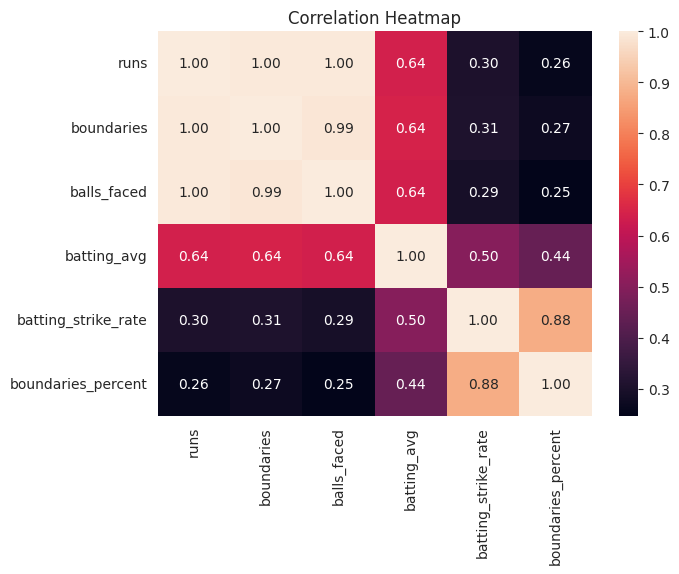

In [7]:
cols= ['runs','boundaries','balls_faced','batting_avg','batting_strike_rate','boundaries_percent']


plt.figure(figsize=[7,5])
sns.heatmap(df[cols].corr(),annot=True,fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Linear Model

In [8]:
X = df[['balls_faced']]
y = df['runs']

model = LinearRegression()

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)
model.fit(X_train,y_train)

print('intercept :',round(model.intercept_,2))
print('Slope:',round(model.coef_[0],4))


intercept : -15.33
Slope: 1.2844


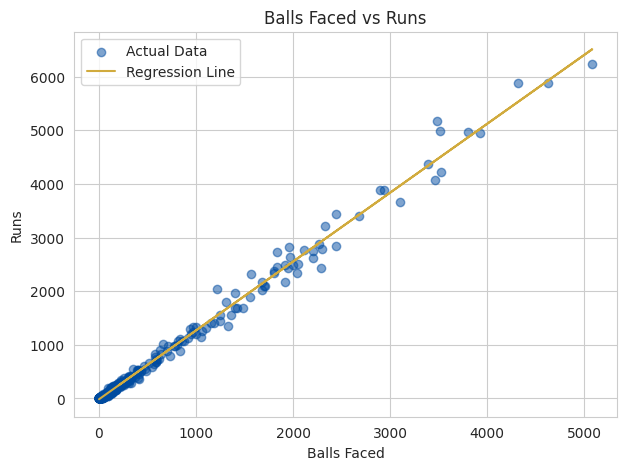

In [9]:
plt.figure(figsize=[7,5])
plt.scatter(X_train,y_train,color=NAVY,alpha=0.5,label='Actual Data')
plt.plot(X_train,model.predict(X_train),color=GOLD,label='Regression Line')
#plt.plot(X_train,y_train,color=GOLD,label='Regression Line')
plt.xlabel('Balls Faced')
plt.ylabel('Runs')
plt.title('Balls Faced vs Runs')
plt.legend()
plt.show()

In [10]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'balls_faced':X_test['balls_faced'].values,
    'actul_runs':y_test.values,
    'predicted_runs':np.round(y_pred,1)
})
comparison.head(10)

,balls_faced,actul_runs,predicted_runs
0,434,522,542.1
1,27,40,19.3
2,57,76,57.9
3,31,21,24.5
4,552,663,693.6
5,865,985,1095.6
6,26,34,18.1
7,9,12,-3.8
8,18,20,7.8
9,703,920,887.6


In [11]:
new_player = pd.DataFrame({'balls_faced':[100,300,600]})
new_pred = model.predict(new_player)

for balls,runs in zip(new_player['balls_faced'],new_pred):
  print(f'Balls Faced= {balls} -> predicted runs = {runs:.0f}')

Balls Faced= 100 -> predicted runs = 113
Balls Faced= 300 -> predicted runs = 370
Balls Faced= 600 -> predicted runs = 755


# Multi Linear model

In [16]:
feature = ['stumpings','matches','batting_avg','batting_strike_rate','catches']
feature = ['balls_faced','boundaries','balls_bowled','stumpings','batting_strike_rate']

X_multi = df[feature]
y_multi = df['runs']

multi_model = LinearRegression()

X_train_m,X_test_m,y_train_m,y_test_m = train_test_split(X_multi,y_multi,test_size=0.2,random_state=42)
multi_model.fit(X_train_m,y_train_m)

print('intercept :',round(model.intercept_,2))

for f,c in zip(feature,multi_model.coef_):
    print(f" {f} Slope: {c:.4f}")

intercept : -15.33
 balls_faced Slope: 0.6805
 boundaries Slope: 3.5326
 balls_bowled Slope: 0.0045
 stumpings Slope: 2.2614
 batting_strike_rate Slope: 0.1359


In [13]:
y_pred_multi = multi_model.predict(X_test)

pd.DataFrame({
    'actual':y_test_m.values[:10],
    'pridicted':np.round(y_pred_multi[:10],1)
})

,actual,pridicted
0,522,542.1
1,40,19.3
2,76,57.9
3,21,24.5
4,663,693.6
5,985,1095.6
6,34,18.1
7,12,-3.8
8,20,7.8
9,920,887.6


In [14]:
def adjusted_r2(r2,n,p):
  return 1-(1-r2)*(n-1)/(n-p-1)

def evaluate(name,y_true,y_pred,n_features):

    mae = mean_absolute_error(y_true,y_pred)
    mse = mean_squared_error(y_true,y_pred)
    rmse = root_mean_squared_error(y_true,y_pred)
    r2 = r2_score(y_true,y_pred)
    adj_r2 = adjusted_r2(r2,len(y_true),n_features)

    print(f"------{name}------")
    print(f'MAE: {mae:.2f}')
    print(f"MSE: {mse:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"R2: {r2:.4f}")
    print(f"Adjusted R2 : {adj_r2:.4f}\n")
    return {"model":name,"MAE":mae,"MSE":mse,"RMSE":rmse,"R2":r2,"Adj_R2":adj_r2}



In [15]:
results =[]

results.append(evaluate('Simple Linear Regression',y_test,y_pred,n_features=1))
results.append(evaluate('Multiple Linear Regression',y_test_m,y_pred_multi,n_features=14))

------Simple Linear Regression------
MAE: 33.81
MSE: 3246.97
RMSE: 56.98
R2: 0.9968
Adjusted R2 : 0.9967

------Multiple Linear Regression------
MAE: 33.81
MSE: 3246.97
RMSE: 56.98
R2: 0.9968
Adjusted R2 : 0.9964

